# TARANG: Grating Couplers

In [1]:
# ---- Logging ---- #
from tarang import configure_logging, set_tidy3d_output

configure_logging(level="INFO")
set_tidy3d_output(False)

# ---- Importing Media ---- #
from media import get_medium

SiN = get_medium(
    "si3n4",
    (0.600, 1.200),
)

SiO2 = get_medium(
    "sio2",
    (0.600, 1.200)
)

Si = get_medium(
    "si",
    (0.600, 1.200),
    tolerance = 1e-5
)

Air = get_medium(
    "air",
    (0.600, 1.200)
)

2026-09-19 02:56:26,761 - tarang.media.medium_helper - INFO -  Cache HIT for si3n4. Reusing Luke_Si3N4_f18474fd.json (Fit range: [0.6, 1.2], RMS: 2.94e-15, Poles allowed: 10).
2026-09-19 02:56:26,775 - tarang.media.medium_helper - INFO -  Cache HIT for sio2. Reusing Nyakuchena_fusedSilica_86882360.json (Fit range: [0.6, 1.2], RMS: 5.61e-07, Poles allowed: 10).
2026-09-19 02:56:26,787 - tarang.media.medium_helper - INFO -  Cache MISS for si. Existing entries failed validation: ['insufficient_max_poles', 'insufficient_accuracy']. Fitting data...
2026-09-19 02:56:26,793 - tarang.media.medium_helper - INFO -  Running local fitter for si (up to 10 poles)...


2026-09-19 02:57:50,308 - tarang.media.medium_helper - INFO -  si fit complete! RMS Error: 8.98e-06
2026-09-19 02:57:50,313 - tarang.media.medium_helper - INFO -  si cached new fit to Wang_Si_25C_96427beb.json and updated manifest.

2026-09-19 02:57:50,314 - tarang.media.medium_helper - INFO -  Bypassing file system for air. Returning dispersionless vacuum medium (n=1.0)...


## Grating Coupler: Example Geometry

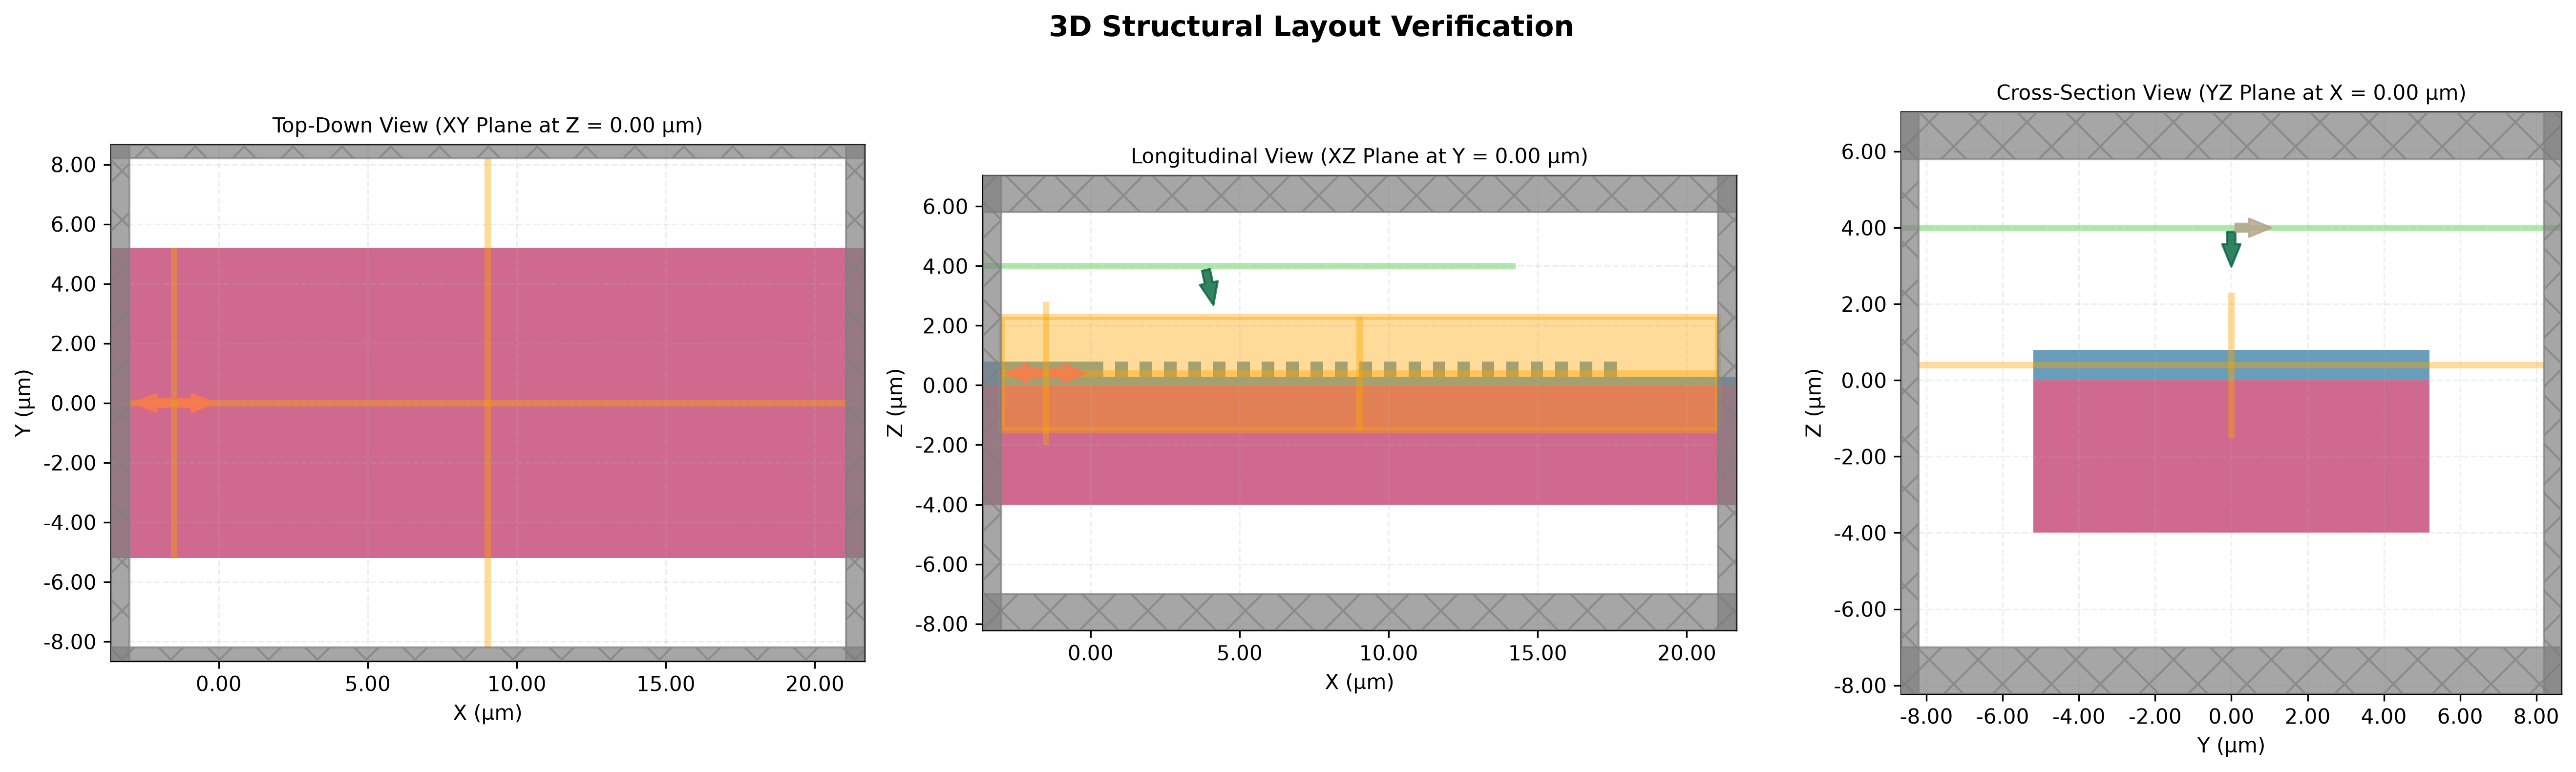

2026-08-06 03:40:42,329 - utilities.sim_plotter - INFO - [Visualizer] 3D orthogonal layout sheet saved to: example_results/grating_coupler/example_3d.png


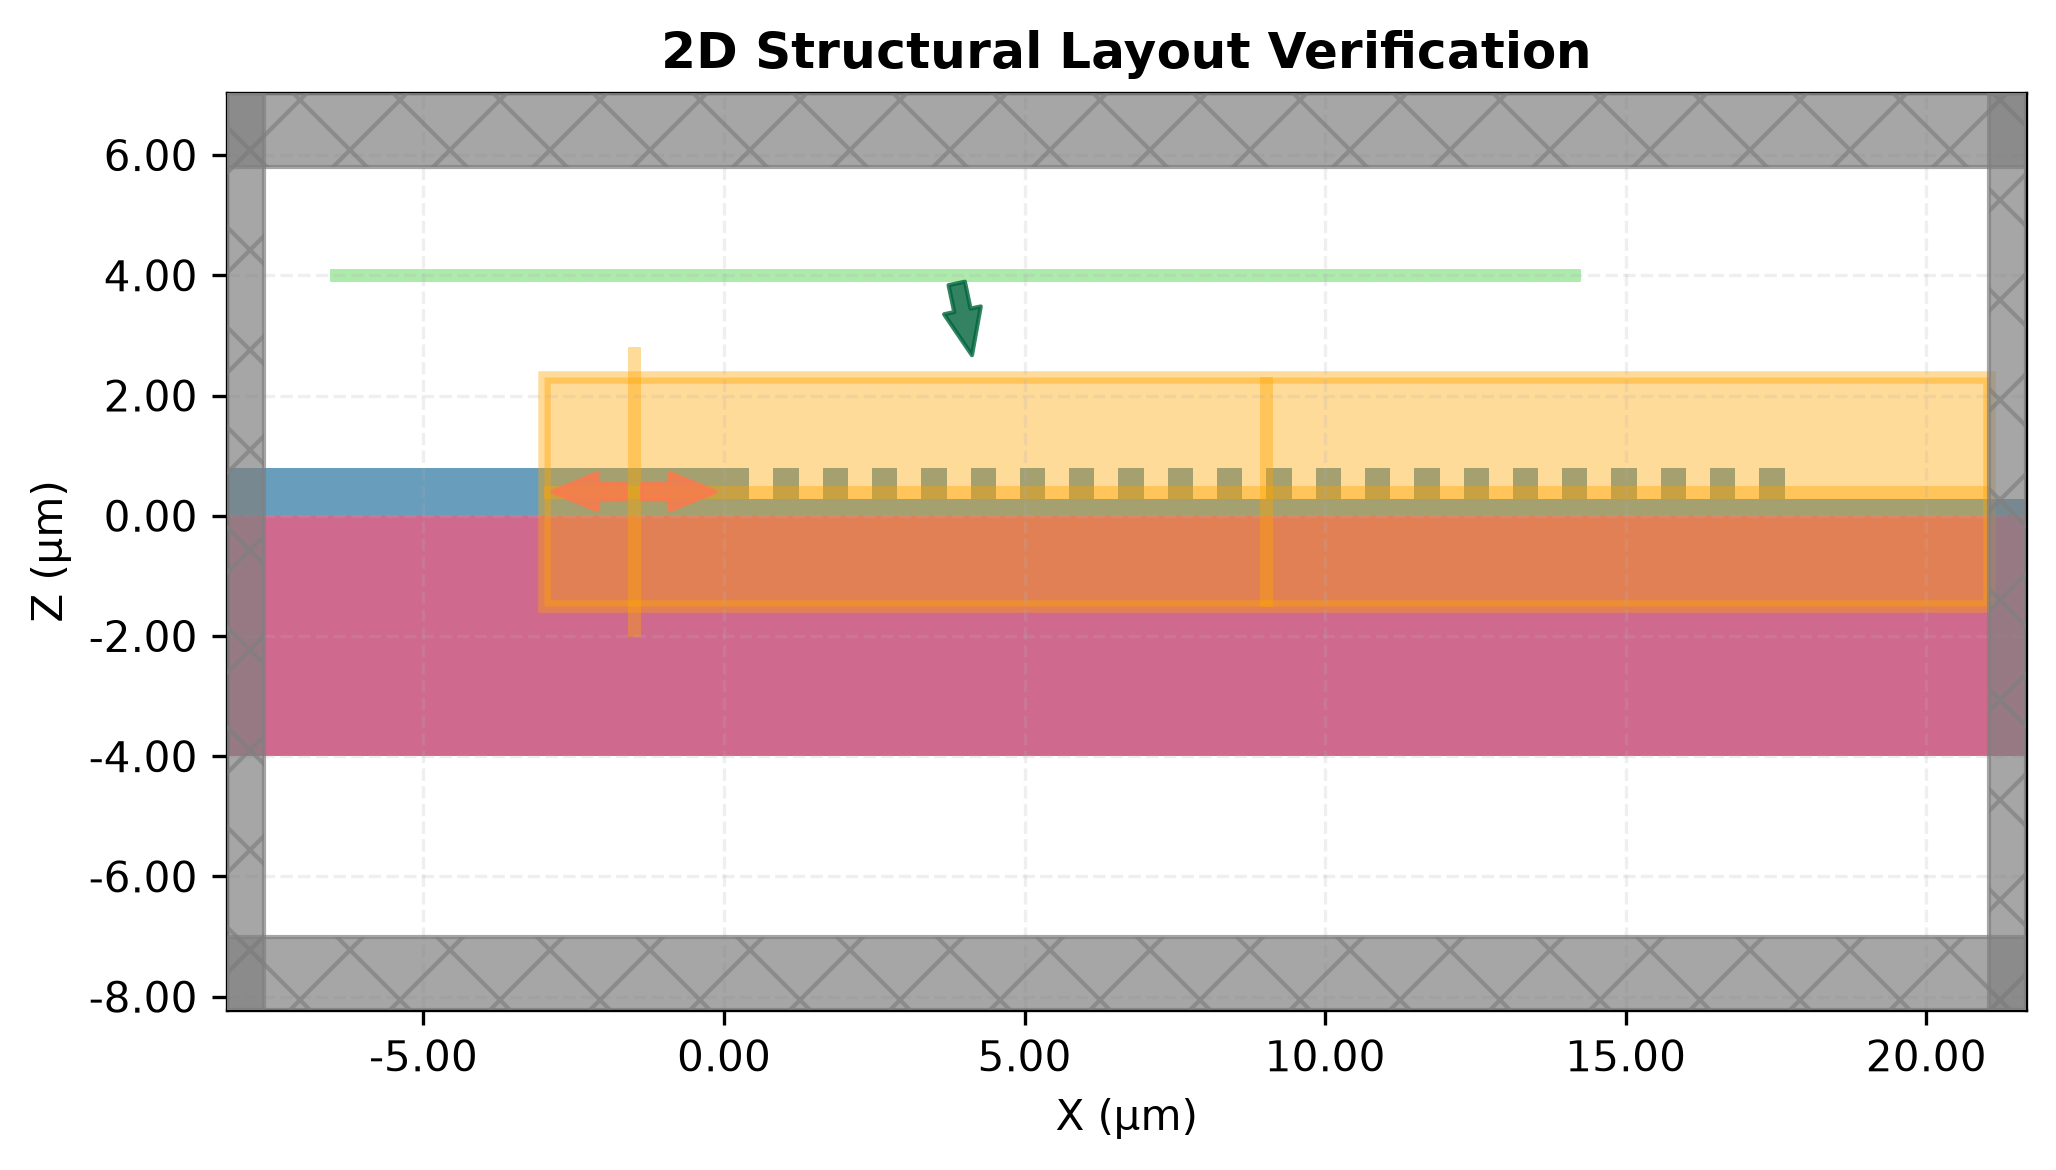

2026-08-06 03:40:42,864 - utilities.sim_plotter - INFO - [Visualizer] 2D geometry layout map saved to: example_results/grating_coupler/example_2d.png


In [3]:
# ---- Defining the Geometry of the Grarting Coupler ---- #

from geometries import grating_coupler
from utilities import sim_plotter
from grating_coupler import GratingConfig, GratingCoupler

from pathlib import Path
import numpy as np

example_config = GratingConfig(
    wavelength_um=1.550,    # Central wavelength (μm)
    theta_deg=-12.0,        # Fiber incidence angle (degrees off-vertical)
    mfd=10.4,               # Mode Field Diameter (Standard SMF-28)
    source_x=3.8419,        # Fiber beam center X position
    source_gap=2.0,         # Distance between fiber source and top cladding

    # Substrate & Layer Geometry
    core_height=0.800,      # Core thickness (μm)
    top_cladding_height=2.0,    # Air/Cladding buffer height above core
    box_height=4.0,         # Buried Oxide (BOX) thickness
    handle_height=8.0,   # Silicon handle thickness

    # Grating Teeth Dimensions
    etch_depth=0.5136,      # Partial etch depth (μm)
    period=0.8201,          # Grating pitch/period (μm)
    ff=0.5136,              # Fill factor (50% tooth, 50% groove)
    n_teeth=22,             # Total number of grating teeth
    w_grating=10.4,        # Transverse width for 3D runs

    # Source & Domain Settings
    pol_angle=np.pi/2,          # 0.0 = TE polarization
    buffer=3.0              # Domain margin buffer
)

example_grating_coupler_3d: GratingCoupler = grating_coupler.get_active_simulation(
    config=example_config,
    core_medium=SiN,
    box_medium=SiO2,
    handle_medium=None,  
    top_cladding_medium=Air,    # Air-clad (or pass SiO2 for oxide clad)
    is_3d=True           
)

example_grating_coupler_2d : GratingCoupler = grating_coupler.get_active_simulation(
    config=example_config,
    core_medium=SiN,
    box_medium=SiO2,
    handle_medium=None,
    top_cladding_medium=Air,
    is_3d=False
)

sim_plotter.display_3d(
    device = example_grating_coupler_3d,
    output_path = Path("example_results/grating_coupler/example_3d.png"),
    show = True,
    save = True
)

sim_plotter.display_2d(
    device=example_grating_coupler_2d,
    output_path=Path("example_results/grating_coupler/example_2d.png"),
    show = True,
    save = True
)

## Grating Coupler: Analytics

### Grating Coupler Efficiency

In [4]:
# ---- Grating Coupler Analytics ---- #

# 1) Coupler efficiency
"""
    The path that is passed to these functions is where the simulation results
    are stored locally after being run on the Tidy3D servers. This ensures that
    if the same configuration is requested more than once, only the first request
    is passed to the Tidy3D servers, and the rest are served from the local data store.

    We have noted that Tidy3D servers do carry out a server-side search to ensure that
    no two simulations are run twice. This layer of local-searching reduces
    latency.

    PROBLEM: As of now the simulation saves are indifferent to the media used to
    build the simulation. This is likely to be corrected with an update to the
    Medium handling architecture.
"""
example_grating_coupler_2d.get_efficiency(Path("example_results/grating_coupler/"))
example_grating_coupler_3d.get_efficiency(Path("example_results/grating_coupler/"))

2026-08-06 03:40:45,684 - root - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/grating_coupler/2D_p_0.8201_dc_0.5136_e_0.5136_n_22_w_10.4000_ch_0.8000_clh_2.0000_bh_4.0000_sh_8.0000_t_-12.0000_mfd_10.4000_sx_3.8419_sg_2.0000_wl_1.5500_pol_1.5708_b_3.0000/raw_simulation_data.hdf5...
2026-08-06 03:40:45,925 - root - INFO - [Analytics] Extracting scattering coefficients from 'mode monitor'...
2026-08-06 03:40:45,933 - root - INFO - [Analytics] Target mode audit completed.
	Coupling Efficiency: 22.27%
	Insertion Loss:      -6.52 dB
2026-08-06 03:40:45,934 - root - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/grating_coupler/3D_p_0.8201_dc_0.5136_e_0.5136_n_22_w_10.4000_ch_0.8000_clh_2.0000_bh_4.0000_sh_8.0000_t_-12.0000_mfd_10.4000_sx_3.8419_sg_2.0000_wl_1.5500_pol_1.5708_b_3.0000/raw_simulation_data.hdf5...
2026-08-06 03:40:46,072 - root - INFO - [Analytics] Extracting scattering coefficients from 'mode monitor'...

0.1851130485415452

### Field plots

2026-08-06 03:40:49,681 - root - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/grating_coupler/2D_p_0.8201_dc_0.5136_e_0.5136_n_22_w_10.4000_ch_0.8000_clh_2.0000_bh_4.0000_sh_8.0000_t_-12.0000_mfd_10.4000_sx_3.8419_sg_2.0000_wl_1.5500_pol_1.5708_b_3.0000/raw_simulation_data.hdf5...
[Analytics] Processing spatial field distributions (2D mode)...
2026-08-06 03:40:49,780 - root - INFO - [Analytics] Skipping 3D-only slice 'field_x_plane' for 2D simulation.
2026-08-06 03:40:50,438 - root - INFO - [Analytics] Exported field profile slice: spatial_field_field_y_plane.png


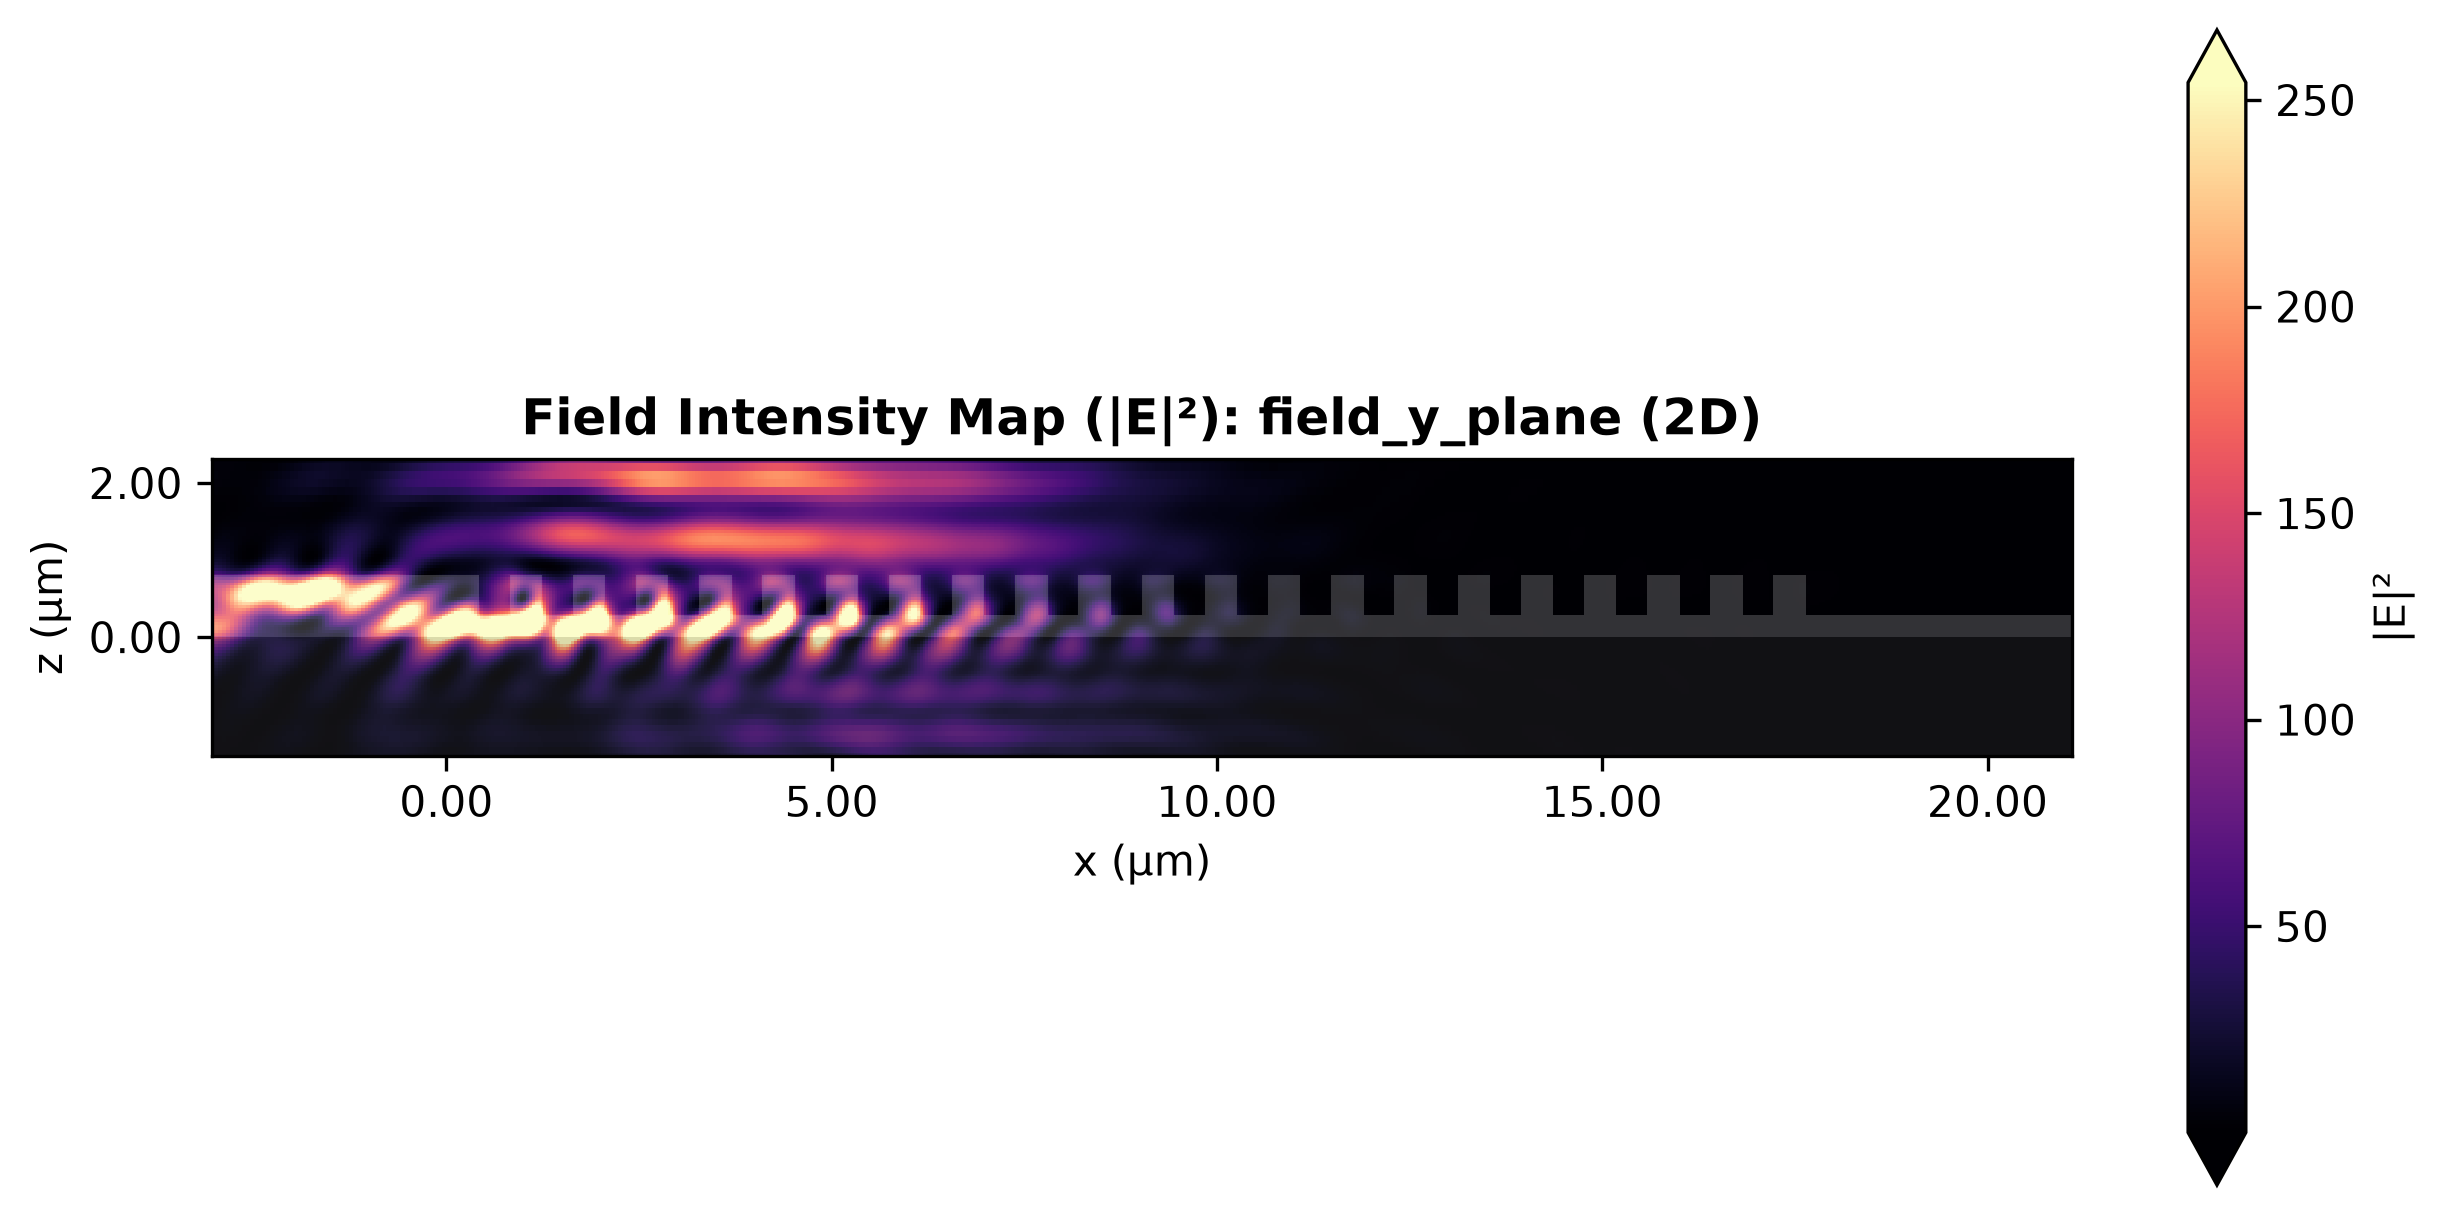

2026-08-06 03:40:50,586 - root - INFO - [Analytics] Skipping 3D-only slice 'field_z_plane' for 2D simulation.


In [5]:
# 2.1) Visualize fields within the 2D coupler
example_grating_coupler_2d.get_fields(Path("example_results/grating_coupler/"))

2026-08-06 03:40:53,199 - root - INFO - [Profiler] Cache hit. Loading existing simulation data from example_results/grating_coupler/3D_p_0.8201_dc_0.5136_e_0.5136_n_22_w_10.4000_ch_0.8000_clh_2.0000_bh_4.0000_sh_8.0000_t_-12.0000_mfd_10.4000_sx_3.8419_sg_2.0000_wl_1.5500_pol_1.5708_b_3.0000/raw_simulation_data.hdf5...
[Analytics] Processing spatial field distributions (3D mode)...
2026-08-06 03:40:53,872 - root - INFO - [Analytics] Exported field profile slice: spatial_field_field_x_plane.png


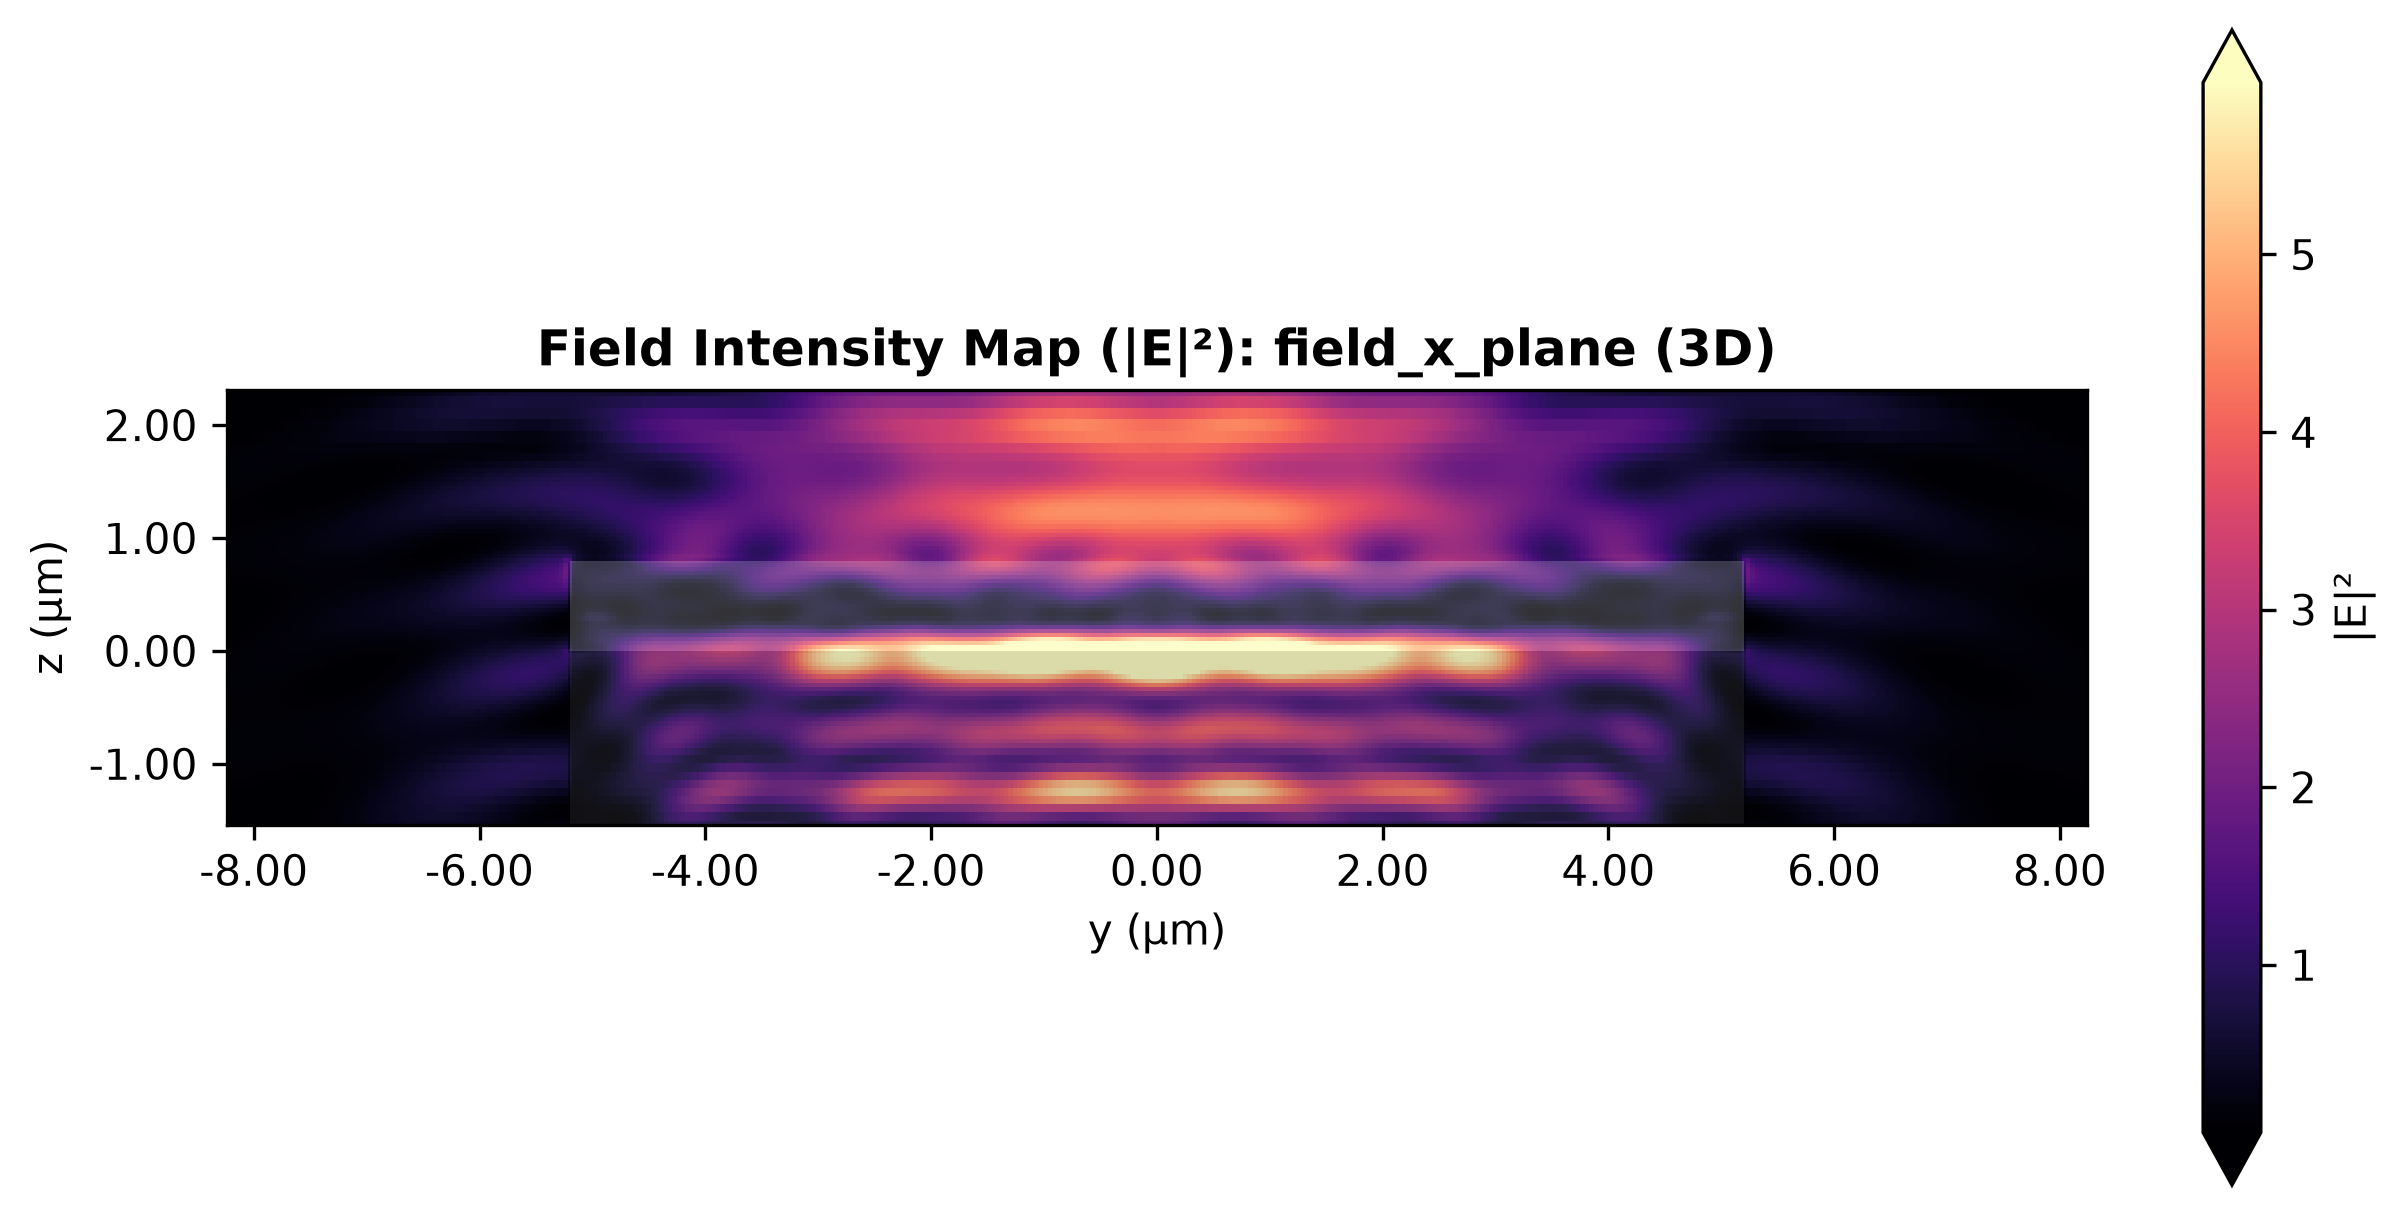

2026-08-06 03:40:54,726 - root - INFO - [Analytics] Exported field profile slice: spatial_field_field_y_plane.png


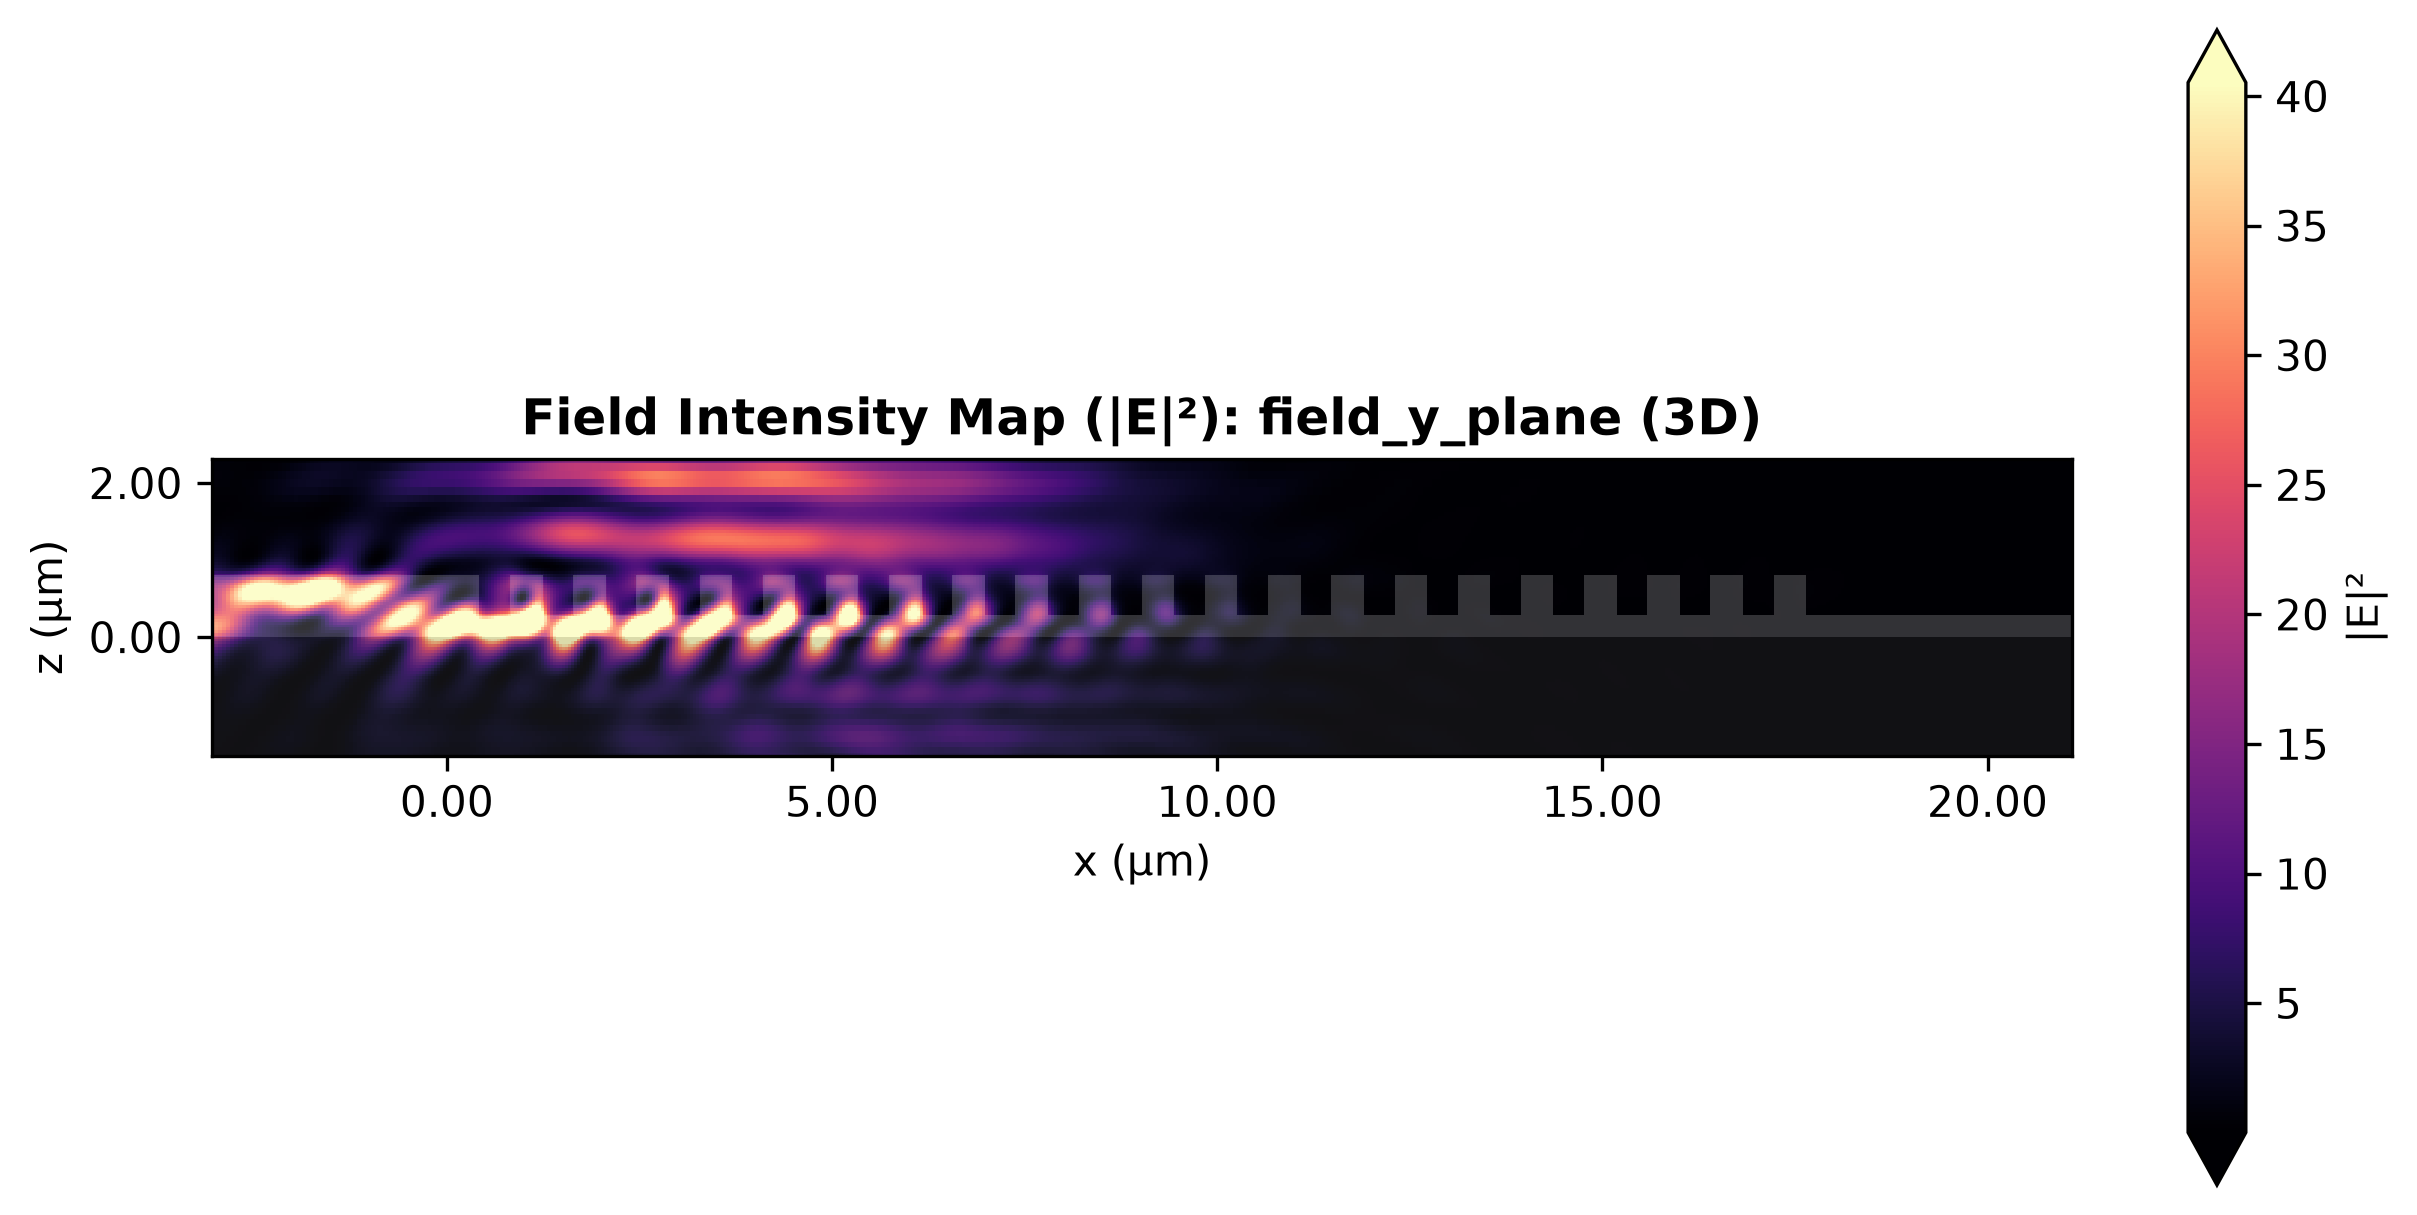

2026-08-06 03:40:56,271 - root - INFO - [Analytics] Exported field profile slice: spatial_field_field_z_plane.png


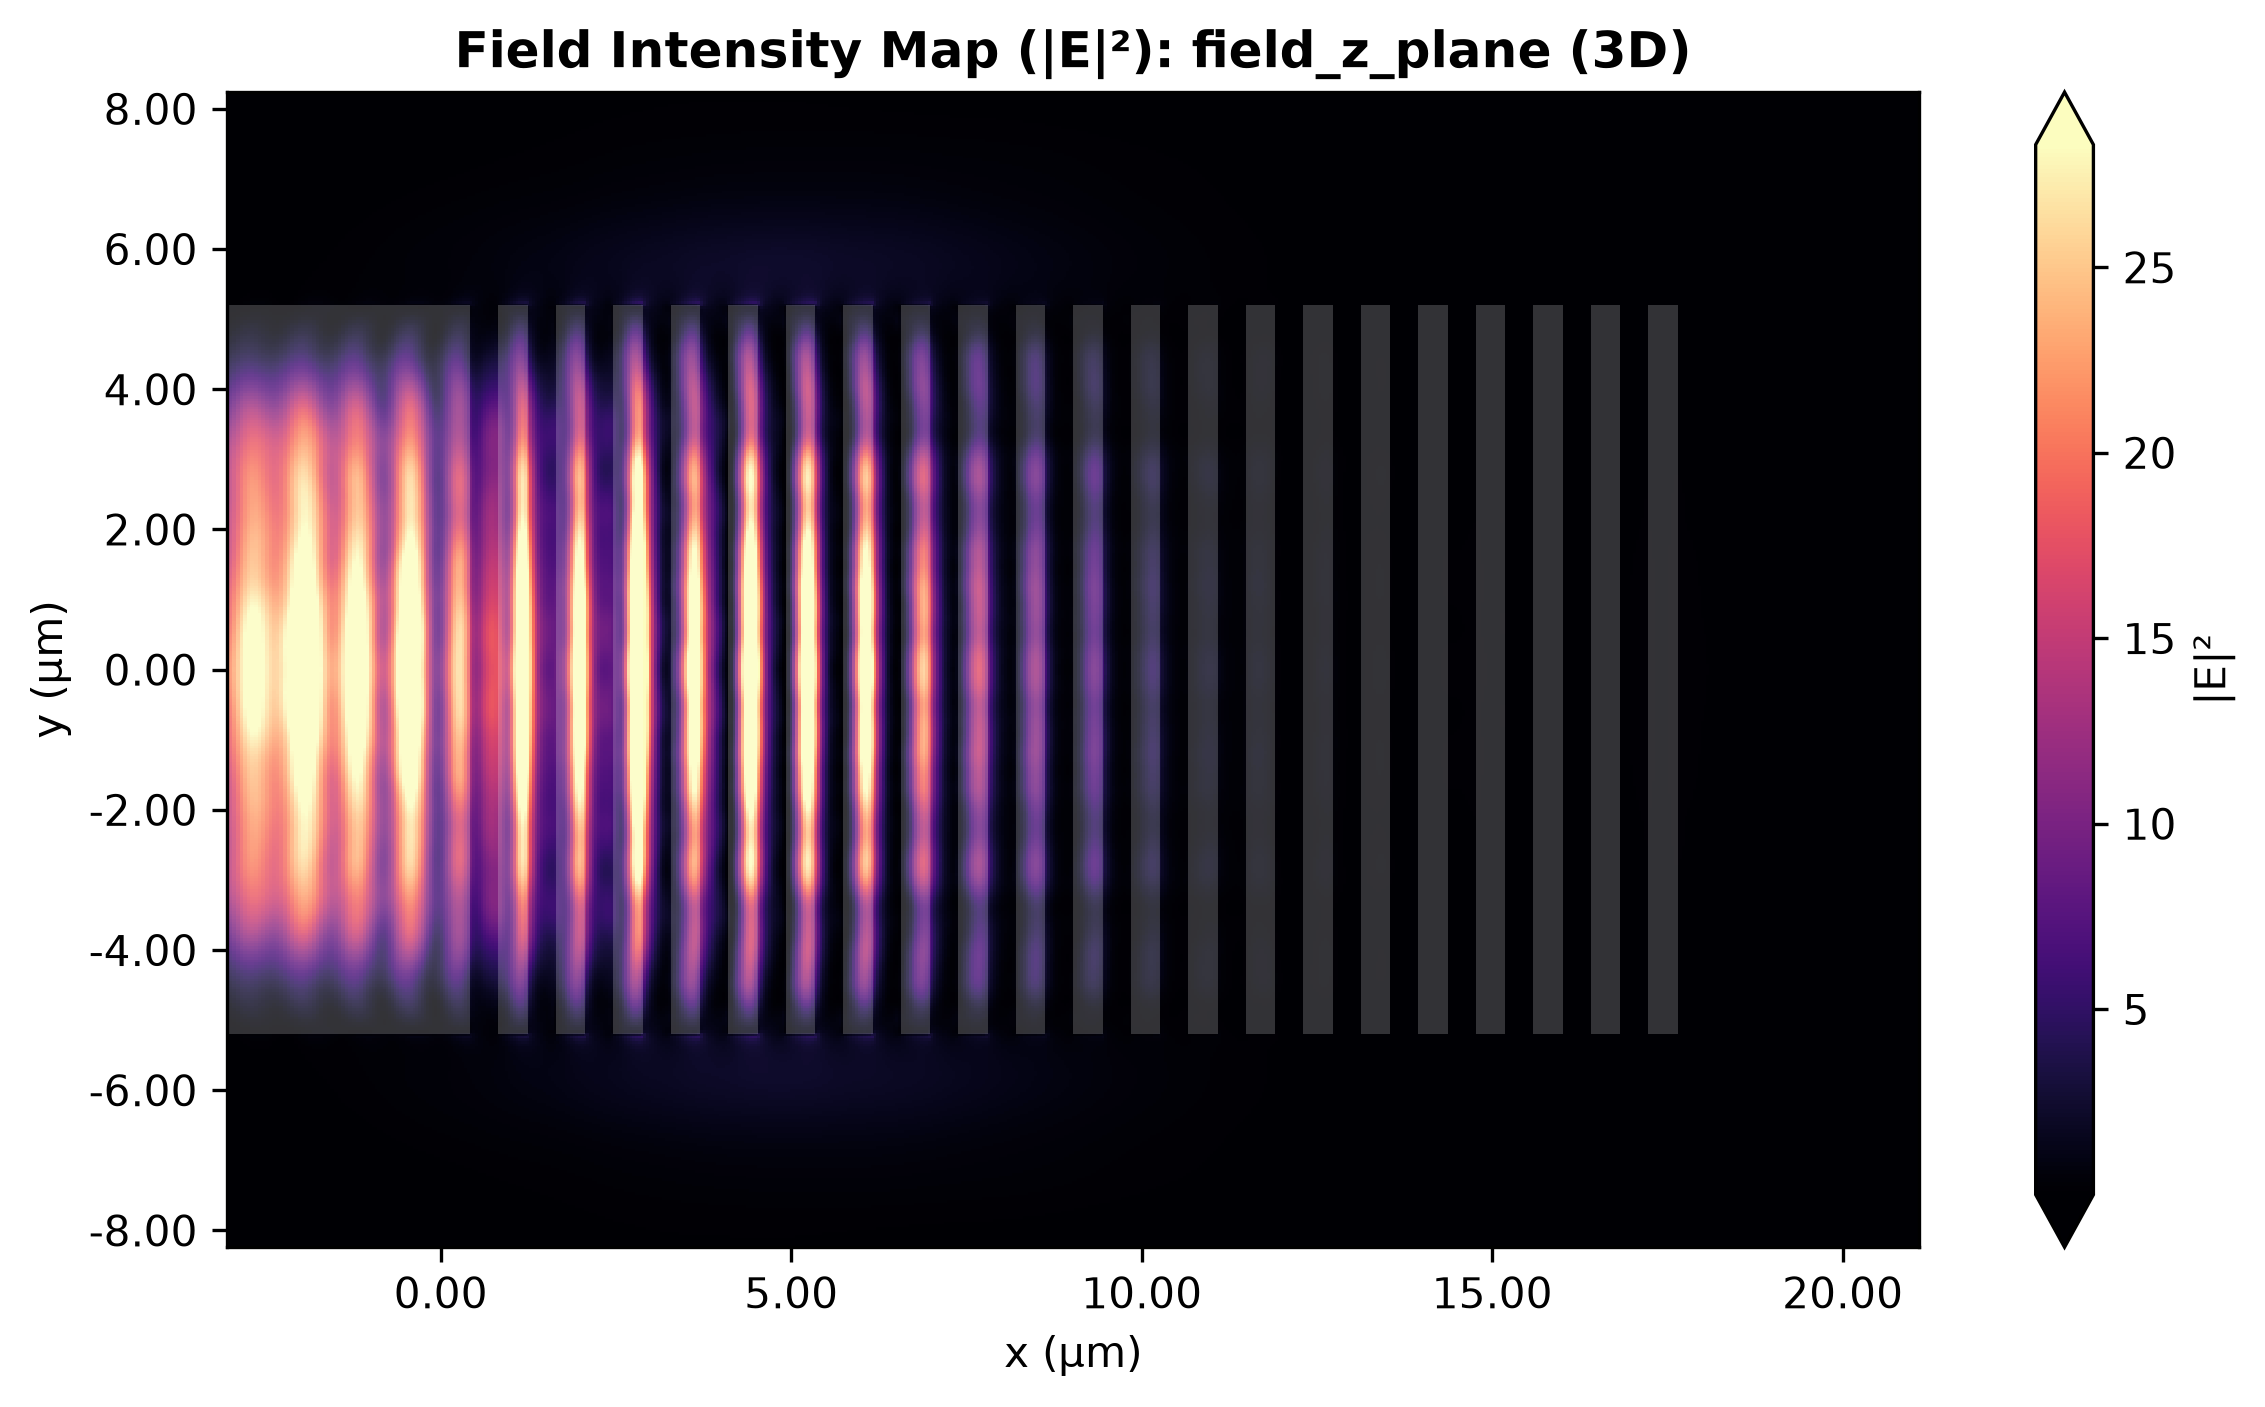

In [6]:
# 2.2) Visualize fields within the 3D coupler
example_grating_coupler_3d.get_fields(Path("example_results/grating_coupler/"))

In [ ]:
from pathlib import Path
from utilities.nested_sampling_post_process import post_process_run

run_dir = Path("example_results/bayesian_demo_budgeted")
results = post_process_run(
    output_dir=run_dir,
    show=True,
)
results


### Corner plot from an ongoing or saved Nested Sampling Run
Run these cells independently: only the directory is needed. While MultiNest occupies another kernel, use this notebook in a separate kernel to inspect its periodically flushed files. `source="auto"` prefers a posterior chain; `source="live"` selects physical live points and labels them as a diagnostic snapshot. Early runs may not have enough flushed rows yet.

Removed no burn in


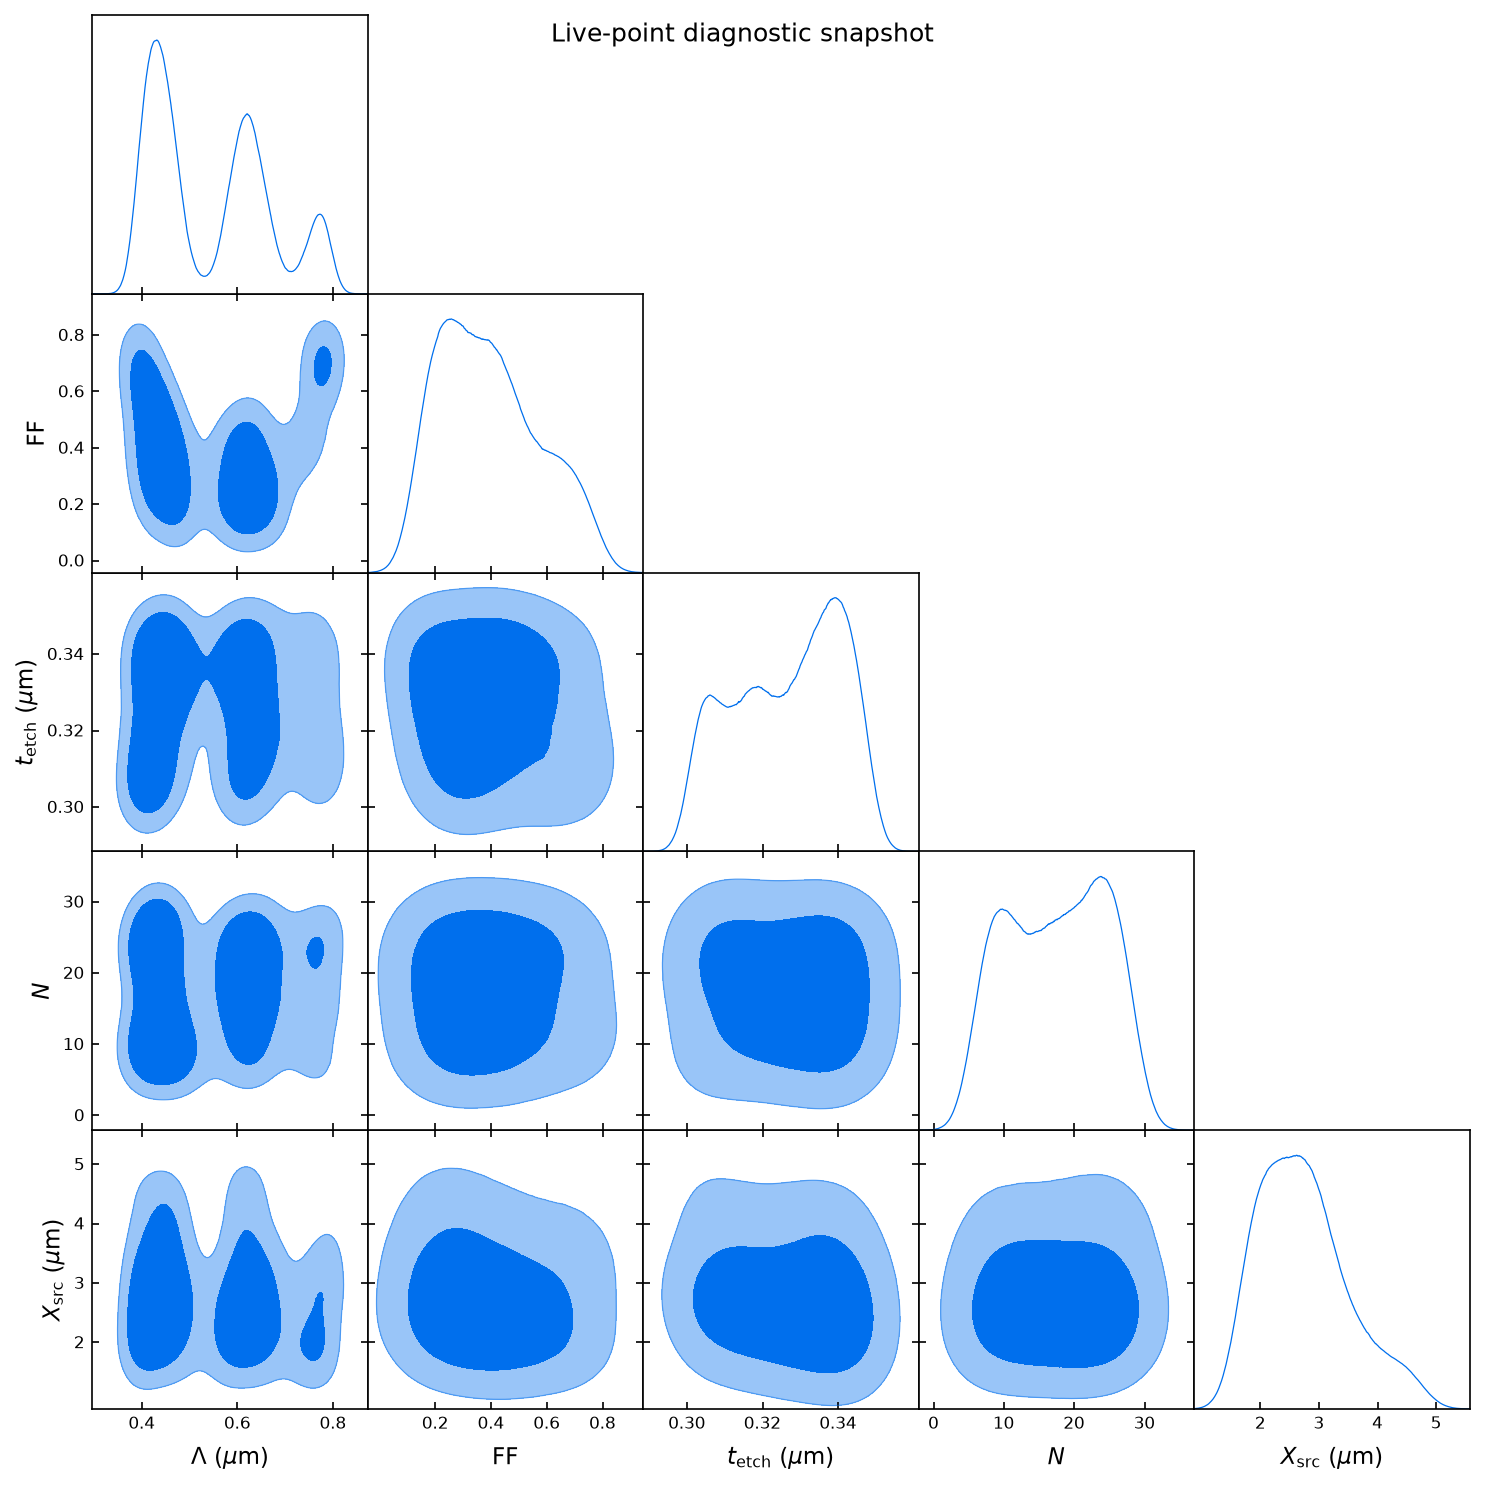

In [1]:
from pathlib import Path
from utilities import plot_corner

corner_result = plot_corner(
    directory=Path("example_results/grating_coupler/example_nested_sampling"),
    source="auto",
    show=True,
)


In [ ]:
# Run this cell when you specifically want the current live-point distribution.
live_result = plot_corner(
    directory=Path("example_results/bayesian_demo_budgeted/chains"),
    source="live",
    output_path=Path("example_results/bayesian_demo_budgeted/live_snapshot.png"),
    show=True,
)
